# US equity strategy: quality, value and residual momentum

Each month we sort US stocks by **quality** (6 accounting ratios), **value** (book-to-market) and **residual momentum**, form 15 size × score portfolios, and tilt a value-weighted portfolio towards the high-score ones with Black-Litterman. Results are compared with the value-weighted market of the same stocks, net of trading costs.

**v2** — changes are switches, to test one at a time: `QUALITY_GP` (§6), `USE_RESMOM` (§9b), `GRADES` and `TE_TARGET` (§13). All `False` / v1 grades = original notebook.

## 0. Setup

In [1]:
import io
import zipfile
from pathlib import Path
from urllib.request import urlopen

import cvxpy as cp
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.covariance import LedoitWolf

RAW, CACHE, FIG, TAB = Path("data/raw"), Path("data/processed"), Path("results/figures"), Path("results/tables")
CACHE.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. CRSP: prices and returns

Monthly CRSP file. When a stock has several rows in a month, we keep the description in force at month-end and add up the dividends. A stock is **eligible** at $t$ if it is a US common stock on NYSE / AMEX / NASDAQ with a price of at least \$5.

In [2]:
START, END = "1963-01-01", "2025-12-31"
MIN_PRICE  = 5                                                       # USD

cache = CACHE / "crsp_monthly.parquet"
if not cache.exists():
    pd.read_csv(RAW / "wdnnuxgrqakbd49j.csv", parse_dates=["MthCalDt", "SecInfoStartDt"]).to_parquet(cache)
FILTERS = {"ShareType": ["NS"], "SecurityType": ["EQTY"], "SecuritySubType": ["COM"], "USIncFlg": ["Y"],
           "IssuerType": ["ACOR", "CORP"], "PrimaryExch": ["N", "A", "Q"], "ConditionalType": ["RW"],
           "TradingStatusFlg": ["A"]}
COLUMNS = ["PERMNO", "PERMCO", "MthCalDt", "SecInfoStartDt", "MthRet", "MthPrc", "ShrOut", "DisDivAmt", "SICCD", *FILTERS]
crsp = pd.read_parquet(cache, columns=COLUMNS)                                # only the columns used (memory)
crsp = crsp[crsp["MthCalDt"].between(START, END)].copy()
crsp["SICCD"] = pd.to_numeric(crsp["SICCD"], errors="coerce")

# One row per stock and month
crsp["DisDivAmt"] = crsp.groupby(["PERMNO", "MthCalDt", "SecInfoStartDt"])["DisDivAmt"].transform("sum", min_count=1)
crsp["in_force"]  = crsp["SecInfoStartDt"] <= crsp["MthCalDt"]
crsp = crsp.sort_values(["in_force", "SecInfoStartDt"]).drop_duplicates(["PERMNO", "MthCalDt"], keep="last")
crsp["date"] = crsp["MthCalDt"] + pd.offsets.MonthEnd(0)
crsp["me"]   = crsp["MthPrc"].abs() * crsp["ShrOut"] / 1000          # market cap, million USD

crsp["eligible"] = np.logical_and.reduce([crsp[c].isin(v) for c, v in FILTERS.items()]
                                         + [crsp["MthPrc"].abs() >= MIN_PRICE, crsp["me"] > 0])
crsp = crsp[crsp.groupby("PERMNO")["eligible"].transform("any")]

# Matrices: stocks in rows, months in columns
mat      = lambda col: crsp.pivot(index="PERMNO", columns="date", values=col).astype(float)
ret, prc, me, permco = mat("MthRet"), mat("MthPrc").abs(), mat("me"), mat("PERMCO")
div, sic = mat("DisDivAmt").fillna(0), mat("SICCD")
eligible = mat("eligible").eq(1)

assert not crsp.duplicated(["PERMNO", "date"]).any()
crsp = crsp[["PERMNO", "PERMCO", "date", "MthCalDt", "me", "eligible", "PrimaryExch"]]   # keep what is used later
print(f"{ret.shape[0]:,} stocks x {ret.shape[1]} months, {eligible.sum().mean():,.0f} eligible stocks per month")

23,717 stocks x 756 months, 3,403 eligible stocks per month


## 2. Delisting returns

When a stock trades until the end of month $t$ and delists in $t+1$ without a new row, CRSP puts the delisting return in the return of $t$. We move it to $t+1$, so it is not known in advance and the investor who holds the stock earns it.

In [3]:
last_day = crsp.groupby("date")["MthCalDt"].transform("max")                  # last trading day of the month
last_row = crsp["date"].eq(crsp.groupby("PERMNO")["date"].transform("max"))
ends     = crsp[last_row & crsp["MthCalDt"].eq(last_day) & crsp["date"].lt(ret.columns[-1])]

ret_price = (prc + div) / prc.shift(1, axis=1) - 1                            # return from prices and dividends only
split     = (ends.assign(x=1).pivot(index="PERMNO", columns="date", values="x").reindex_like(ret).eq(1)
             & eligible & ret.notna() & ret_price.notna())
ret_delist = ((1 + ret) / (1 + ret_price) - 1).where(split).shift(1, axis=1)  # moved to t+1
ret = ret.mask(split, ret_price).mask(ret_delist.notna(), ret_delist)
print(f"Delisting returns moved to t+1: {split.sum().sum():,}")
del ret_price, ret_delist, split, ends, last_day, last_row                    # free memory

Delisting returns moved to t+1: 2,107


## 3. Trading halts

If a stock we hold has no return at $t+1$ (trading halt), it earns the move from its last price to its next price. If it is never priced again, it is worth nothing.

In [4]:
NEVER_PRICED = -1.0                                                           # return of a stock never priced again

held   = eligible.shift(1, axis=1, fill_value=False)
gap    = held & ret.isna()
cumdiv = div.cumsum(axis=1)
r_gap  = (prc.bfill(axis=1) + cumdiv.where(prc.notna()).bfill(axis=1) - cumdiv.shift(1, axis=1)) / prc.shift(1, axis=1) - 1
r_gap  = r_gap.fillna(pd.DataFrame(np.where(permco.notna(), NEVER_PRICED, 0.0), index=ret.index, columns=ret.columns))
n_prc  = prc.notna().cumsum(axis=1).shift(1, axis=1)
inside = n_prc.eq(n_prc.where(gap).ffill(axis=1)) & ~gap & ret.notna()       # returns inside the gap: already counted
ret    = ret.mask(inside).mask(gap, r_gap)

assert not (held & ret.isna()).any().any(), "A held stock has no return"
print(f"Missing returns filled: {gap.sum().sum():,}")
del held, gap, cumdiv, r_gap, n_prc, inside, prc, div, permco                 # free memory

Missing returns filled: 283


## 4. Compustat: accounting data

A report is used only **6 months after the fiscal year end** (so it is public), for at most 12 months. A firm is used from its 2nd year in Compustat (backfill bias). Book equity $BE = CEQ + TXDITC$.

In [5]:
LAG, MAX_AGE = 6, 12                                                          # months

USE  = ["GVKEY", "LPERMNO", "datadate", "fyear", "curcd", "ceq", "txditc", "ib", "at", "revt", "cogs", "dlc", "dltt", "act", "lct"]
comp = pd.read_csv(RAW / "a8rafgip2h9dugyk.csv", usecols=USE, parse_dates=["datadate"], dtype={"GVKEY": str})
comp = comp.rename(columns={"LPERMNO": "PERMNO"})
comp = comp[comp["curcd"].eq("USD")]
comp = comp[comp.groupby("GVKEY")["datadate"].rank(method="dense") >= 2]     # from the 2nd year
comp["be"] = comp["ceq"] + comp["txditc"].fillna(0)

prev = comp.dropna(subset="fyear").sort_values("datadate").drop_duplicates(["GVKEY", "fyear"], keep="last")
prev = prev[["GVKEY", "fyear", "revt"]].assign(fyear=lambda d: d["fyear"] + 1).rename(columns={"revt": "revt_lag"})
comp = comp.merge(prev, on=["GVKEY", "fyear"], how="left")                   # revenue of the previous year

comp  = comp[comp["PERMNO"].isin(ret.index)]
avail = comp["datadate"] + pd.offsets.MonthEnd(0) + pd.offsets.MonthEnd(LAG)
comp  = pd.concat([comp.assign(date=avail + pd.offsets.MonthEnd(k)) for k in range(MAX_AGE)])
comp  = comp[comp["date"].isin(ret.columns)].sort_values("datadate").drop_duplicates(["PERMNO", "date"], keep="last")

acc = {v: comp.pivot(index="PERMNO", columns="date", values=v).reindex_like(ret)
       for v in ["ib", "be", "at", "revt", "cogs", "dlc", "dltt", "act", "lct", "revt_lag"]}
assert (comp["date"] >= comp["datadate"] + pd.DateOffset(months=LAG)).all(), "Report used too early"
del comp, prev, avail                                                         # free memory

## 5. Fama-French factors

Downloaded once from the Kenneth French Data Library, in decimals.

In [6]:
URL = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/"


def french(name: str) -> pd.DataFrame:
    """Monthly table of a French data file (months in rows), cached as parquet."""
    path = CACHE / f"french_{name}.parquet"
    if not path.exists():
        with zipfile.ZipFile(io.BytesIO(urlopen(URL + name + "_CSV.zip").read())) as z:
            lines = z.read(z.namelist()[0]).decode("latin-1").splitlines()
        start = next(i for i, line in enumerate(lines) if line.startswith(","))
        end   = next(i for i in range(start + 1, len(lines)) if not lines[i][:6].strip().isdigit())
        df    = pd.read_csv(io.StringIO("\n".join(lines[start:end])), index_col=0) / 100
        df.index   = pd.to_datetime(df.index.astype(str), format="%Y%m") + pd.offsets.MonthEnd(0)
        df.columns = df.columns.str.strip()
        df.to_parquet(path)
    return pd.read_parquet(path)


ff3 = french("F-F_Research_Data_Factors")
ff5 = french("F-F_Research_Data_5_Factors_2x3").assign(UMD=french("F-F_Momentum_Factor")["Mom"])

## 6. Investment universe

Eligible stocks with all the accounting data the score needs. Financials (SIC 6000–6999) have no current ratio. The revenue of the previous year is required only when sales growth is in the score (`QUALITY_GP = False`).

In [7]:
QUALITY_GP = True                                                             # gross profitability (Novy-Marx) instead of sales growth

fin  = sic.ge(6000) & sic.le(6999)
debt = acc["dlc"].add(acc["dltt"], fill_value=0)
universe = (eligible & acc["ib"].notna() & (acc["be"] > 0) & (acc["at"] > 0) & (acc["revt"] > 0)
            & acc["cogs"].notna() & debt.notna() & ((acc["revt_lag"] > 0) | QUALITY_GP)
            & (fin | (acc["act"].notna() & (acc["lct"] > 0))))
print(f"Universe: {universe.sum()[universe.sum() > 0].mean():,.0f} stocks per month")

Universe: 2,602 stocks per month


## 7. Benchmark

Value-weighted portfolio of the universe: weights from the market caps at $t$, return of $t+1$.

In [8]:
nxt     = ret.shift(-1, axis=1)                                               # return of t+1, aligned on t
w_bench = me.where(universe).div(me.where(universe).sum(), axis=1)
bench   = (w_bench * nxt).sum(min_count=1)                                    # indexed by t (NaN in the last month)

## 8. Size buckets

Each month: micro, small or large, by firm market cap, with the 20th and 50th percentiles of NYSE firms as breakpoints.

In [9]:
BREAKPOINTS = [0.20, 0.50]

crsp["me_firm"] = crsp.groupby(["date", "PERMCO"])["me"].transform("sum")     # all share classes of the firm
me_firm = crsp.pivot(index="PERMNO", columns="date", values="me_firm").reindex_like(ret)
nyse    = crsp[crsp["eligible"] & crsp["PrimaryExch"].eq("N")].drop_duplicates(["date", "PERMCO"])
bp      = nyse.groupby("date")["me_firm"].quantile(BREAKPOINTS).unstack().reindex(ret.columns)
size    = pd.DataFrame(np.select([me_firm.lt(bp.iloc[:, 0], axis=1), me_firm.lt(bp.iloc[:, 1], axis=1)],
                                 ["micro", "small"], "large"), index=ret.index, columns=ret.columns).where(universe)
BUCKETS = ["micro", "small", "large"]
del crsp, nyse                                                                # free memory

## 8b. The universe over time

Number of universe stocks and share of the universe market cap in each size bucket, every month.

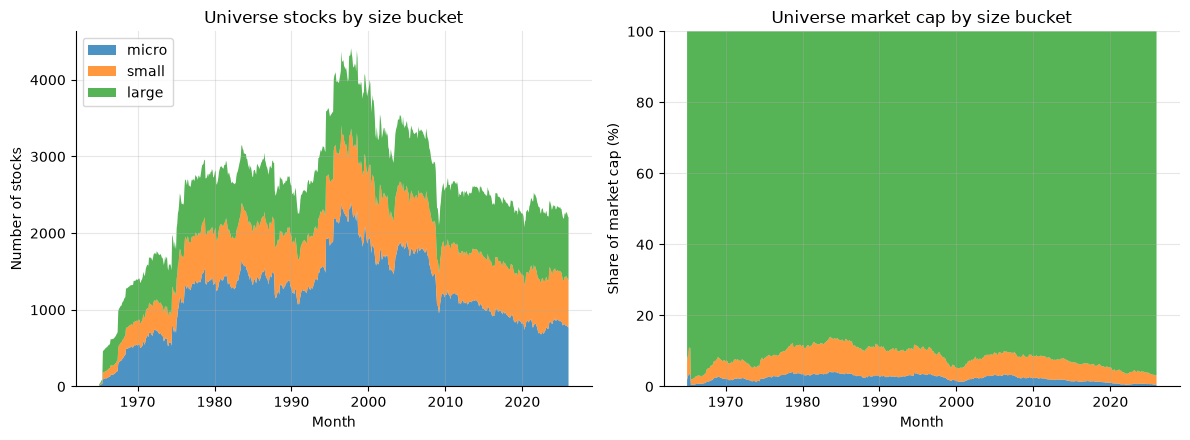

,micro,small,large
Stocks (average),1212.7,636.8,752.3
"Market cap (%, average)",2.3,5.9,91.7


In [10]:
n_stocks = pd.DataFrame({b: size.eq(b).sum() for b in BUCKETS})
n_stocks = n_stocks[n_stocks.sum(axis=1) > 0]
me_share = pd.DataFrame({b: me.where(size.eq(b)).sum() for b in BUCKETS}).loc[n_stocks.index]
me_share = me_share.div(me_share.sum(axis=1), axis=0) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.stackplot(n_stocks.index, n_stocks.T.to_numpy(), labels=BUCKETS, alpha=0.8)
ax1.set(ylabel="Number of stocks", xlabel="Month", title="Universe stocks by size bucket")
ax1.legend(loc="upper left")
ax2.stackplot(me_share.index, me_share.T.to_numpy(), labels=BUCKETS, alpha=0.8)
ax2.set(ylabel="Share of market cap (%)", xlabel="Month", title="Universe market cap by size bucket", ylim=(0, 100))
fig.tight_layout()
fig.savefig(FIG / "v2_universe.pdf")
fig.savefig(FIG / "v2_universe.png", dpi=150)                         # for the README
plt.show()
pd.DataFrame({"Stocks (average)": n_stocks.mean(), "Market cap (%, average)": me_share.mean()}).T.round(1)

## 9. Sectors

Fama-French 12 industries from the SIC code. A sector with too few firms in a month is grouped with "Other".

In [11]:
MIN_SECTOR = 20

with zipfile.ZipFile(io.BytesIO(urlopen(URL + "Siccodes12.zip").read())) as z:
    lines = z.read(z.namelist()[0]).decode("latin-1").splitlines()
ranges, name = [], None
for parts in (line.split() for line in lines):
    if parts and parts[0].isdigit():
        name = parts[1]
    elif parts and "-" in parts[0]:
        ranges.append((name, *map(int, parts[0].split("-"))))

names, lo, hi = (np.array(x) for x in zip(*sorted(ranges, key=lambda r: r[1])))
s      = sic.to_numpy()
k      = (np.searchsorted(lo, s, side="right") - 1).clip(0)                   # last range starting below the SIC code
sector = pd.DataFrame(np.where((s >= lo[k]) & (s <= hi[k]), names[k], "Other"),
                      index=ret.index, columns=ret.columns).where(universe)
n_firms = sector.apply(lambda col: col.map(col.value_counts()))               # firms of the same sector that month
sector  = sector.mask(n_firms < MIN_SECTOR, "Other")
del s, k, n_firms

## 9b. Residual momentum

Momentum of the part of the return the Fama-French 3 factors do not explain (Blitz, Huij & Martens, 2011). At $t$: betas on the last 36 months, then the sum of the residuals from $t-11$ to $t-1$ (the last month is skipped) divided by their volatility. It is designed to be less exposed to UMD than plain momentum; in this sample it still loses more than half of its FF5 alpha when UMD is added (section 11b).

In [12]:
USE_RESMOM = True
RM_WINDOW, RM_FORM, RM_SKIP = 36, 11, 1                                       # months


def residual_momentum(ret: pd.DataFrame, ff: pd.DataFrame, universe: pd.DataFrame,
                      window: int = RM_WINDOW, form: int = RM_FORM, skip: int = RM_SKIP) -> pd.DataFrame:
    """Residual momentum at t, from the returns known at t (universe stocks with a full window only)."""
    f = ff.reindex(ret.columns)
    X = np.column_stack([np.ones(len(f)), f[["Mkt-RF", "SMB", "HML"]].to_numpy()])
    R = ret.sub(f["RF"], axis=1).to_numpy()                                   # excess returns
    U = universe.to_numpy()
    out = np.full(R.shape, np.nan)
    for j in range(window - 1, R.shape[1]):
        Xw, Y = X[j - window + 1:j + 1], R[:, j - window + 1:j + 1]
        ok = U[:, j] & ~np.isnan(Y).any(axis=1)
        if np.isnan(Xw).any() or not ok.any():
            continue
        beta = np.linalg.lstsq(Xw, Y[ok].T, rcond=None)[0]                    # 4 x stocks
        e = (Y[ok] - (Xw @ beta).T)[:, window - form - skip:window - skip]    # residuals t-11 .. t-1
        out[ok, j] = e.sum(axis=1) / e.std(axis=1, ddof=1)
    return pd.DataFrame(out, index=ret.index, columns=ret.columns)


resmom = residual_momentum(ret, ff3, universe) if USE_RESMOM else None
if USE_RESMOM:
    print(f"Residual momentum available for {resmom.notna().sum().sum() / universe.sum().sum():.0%} of universe stock-months")


Residual momentum available for 93% of universe stock-months


## 10. Quality and value scores

Every ratio is turned into a **z-score within its sector and month** (after cutting the 1% extremes). Quality = average of the 6 ratio z-scores; value = z-score of book-to-market; final score = quality + value (+ residual momentum), standardised again.

**Change vs. v1**: *sales growth* is replaced by **gross profitability** $(REVT-COGS)/AT$ (Novy-Marx, 2013). High sales growth predicts *lower* returns (Lakonishok, Shleifer & Vishny, 1994), so it was working against the score.

In [13]:
WINSOR     = 0.01


row, col = np.nonzero(universe.to_numpy())                                    # positions of the universe stocks
key      = [col, sector.to_numpy()[row, col]]                                 # groups: month x sector


def zscore(x: pd.DataFrame, winsor: float = 0.0) -> pd.DataFrame:
    """Z-score of x within each sector and month (universe stocks only)."""
    s = pd.Series(x.to_numpy()[row, col])
    if winsor:
        s = s.clip(s.groupby(key).transform("quantile", winsor), s.groupby(key).transform("quantile", 1 - winsor))
    z = (s - s.groupby(key).transform("mean")) / s.groupby(key).transform("std")
    out = np.full(x.shape, np.nan)
    out[row, col] = z
    return pd.DataFrame(out, index=x.index, columns=x.columns)


ratios = {"ROE":            acc["ib"] / acc["be"],
          "ROA":            acc["ib"] / acc["at"],
          "Gross margin":   (acc["revt"] - acc["cogs"]) / acc["revt"],
          "Debt to equity": -debt / acc["be"],                                # minus: less debt = better
          "Current ratio":  (acc["act"] / acc["lct"]).mask(fin),
          **({"Gross profitability": (acc["revt"] - acc["cogs"]) / acc["at"]} if QUALITY_GP
             else {"Sales growth": acc["revt"] / acc["revt_lag"] - 1})}
z_ratios = [zscore(r.where(universe), WINSOR) for r in ratios.values()]
quality  = zscore(sum(z.fillna(0) for z in z_ratios) / sum(z.notna() for z in z_ratios))
value    = zscore((acc["be"] / me_firm).where(universe), WINSOR)
signals  = [quality, value] + ([zscore(resmom.where(universe), WINSOR).fillna(0).where(universe)] if USE_RESMOM else [])
score    = zscore(sum(signals))                                              # equal weights, no tuning

assert score.notna().eq(universe).all().all(), "Universe stock without a score"
del z_ratios

## 10b. Descriptive statistics of the signals

The ratios are compared within each sector only, because their level differs a lot from one sector to another. First **by sector**: median of each ratio over all universe stock-months of the sector, and its distribution (box: 25th–75th percentiles, whiskers: 5th–95th). Then **over the whole universe** (coverage = share of universe stock-months with a value; no current ratio for financials), and the average monthly correlation of the three scores. All values before winsorisation; debt to equity with its true sign (it enters the score with a minus).

,Stock-months (%),ROE,ROA,Gross margin,Debt to equity,Current ratio,Gross profitability,Book-to-market,Residual momentum
BusEq,13.30,0.09,0.05,0.46,0.15,2.65,0.41,0.37,-0.14
Chems,2.89,0.12,0.06,0.35,0.45,2.21,0.37,0.52,-0.12
Durbl,3.09,0.12,0.06,0.27,0.37,2.36,0.38,0.62,-0.09
Enrgy,3.81,0.09,0.05,0.36,0.51,1.42,0.20,0.59,-0.03
Hlth,6.88,0.08,0.04,0.48,0.21,3.04,0.36,0.28,-0.17
Manuf,14.33,0.11,0.06,0.28,0.42,2.35,0.33,0.67,-0.08
Money,18.49,0.10,0.01,0.49,0.87,NaN,0.04,0.72,-0.01
NoDur,7.42,0.11,0.06,0.33,0.43,2.28,0.43,0.65,-0.05
Other,12.05,0.10,0.05,0.28,0.46,1.69,0.26,0.51,-0.11
Shops,10.83,0.12,0.05,0.29,0.45,1.90,0.53,0.55,-0.14


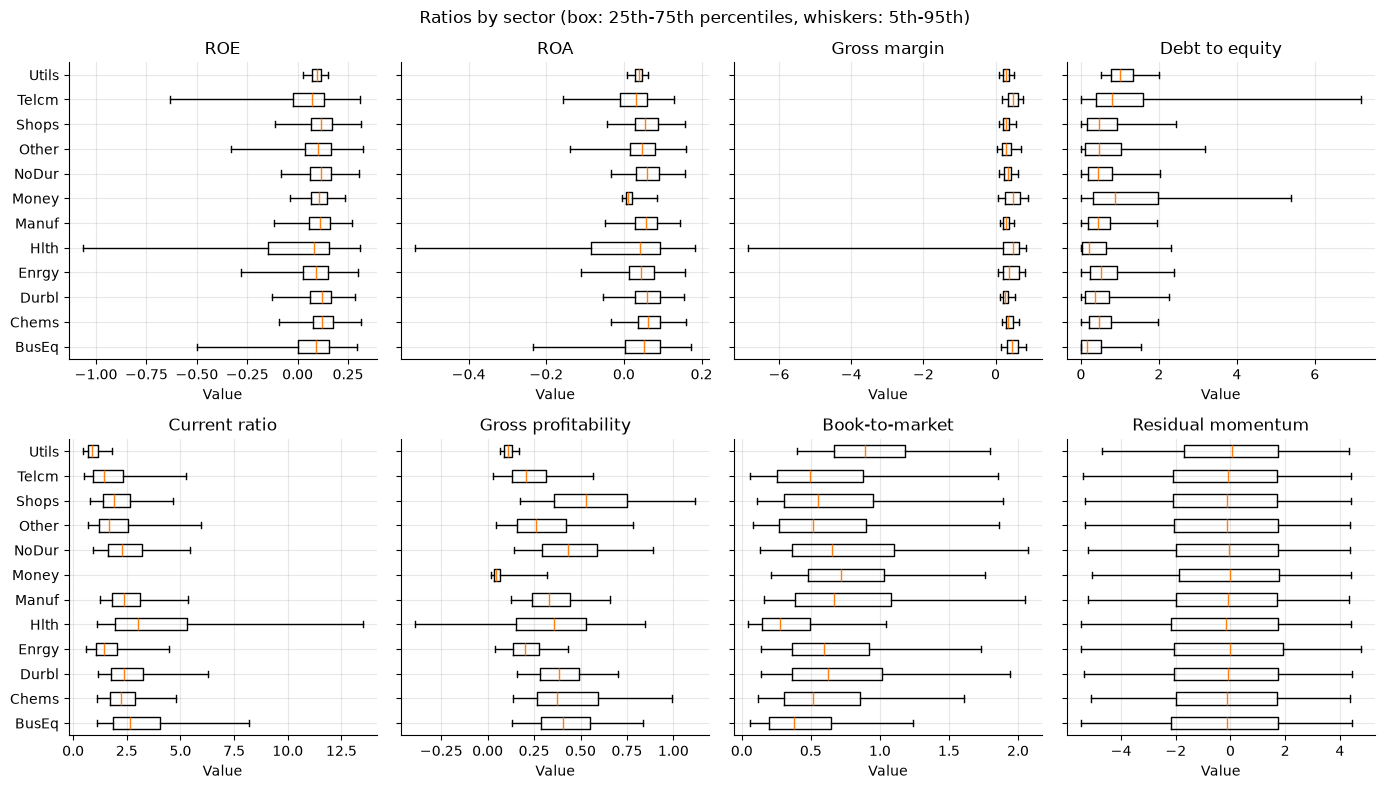

,Coverage (%),P5,P25,Median,P75,P95
ROE,100.00,-0.26,0.05,0.10,0.15,0.28
ROA,100.00,-0.11,0.01,0.04,0.08,0.15
Gross margin,100.00,0.08,0.23,0.35,0.51,0.80
Debt to equity,100.00,0.00,0.14,0.47,1.00,3.13
Current ratio,81.49,0.76,1.42,2.10,3.09,6.60
Gross profitability,100.00,0.03,0.12,0.29,0.47,0.82
Book-to-market,100.00,0.10,0.32,0.58,0.94,1.79
Residual momentum,92.83,-5.25,-2.02,-0.08,1.74,4.40


Average monthly correlation of the scores:


,Quality,Value,Residual momentum
Quality,1.00,-0.25,-0.09
Value,-0.25,1.00,-0.06
Residual momentum,-0.09,-0.06,1.00


In [14]:
raw  = {**ratios, "Debt to equity": -ratios["Debt to equity"], "Book-to-market": acc["be"] / me_firm, **({"Residual momentum": resmom} if USE_RESMOM else {})}
vals = pd.DataFrame({k: v.to_numpy()[row, col] for k, v in raw.items()})       # universe stock-months only
sec  = pd.Series(key[1])                                                      # sector of each stock-month

# === By sector ===
table_sectors = vals.groupby(sec).median()
table_sectors.loc["All"] = vals.median()
table_sectors.insert(0, "Stock-months (%)", sec.value_counts(normalize=True).reindex(table_sectors.index).fillna(1) * 100)
display(table_sectors.round(2))

names = list(table_sectors.index[:-1])
fig, axes = plt.subplots(2, 4, figsize=(14, 8), sharey=True)
for ax, k in zip(axes.flat, raw):
    ax.boxplot([vals.loc[sec.eq(s).to_numpy(), k].dropna() for s in names], orientation="horizontal", whis=(5, 95), showfliers=False)
    ax.set_yticks(range(1, len(names) + 1), names)
    ax.set(title=k, xlabel="Value")
fig.suptitle("Ratios by sector (box: 25th-75th percentiles, whiskers: 5th-95th)")
fig.tight_layout()
fig.savefig(FIG / "v2_ratios_by_sector.pdf")
fig.savefig(FIG / "v2_ratios_by_sector.png", dpi=150)                         # for the README
plt.show()

# === Whole universe ===
desc = vals.quantile([0.05, 0.25, 0.5, 0.75, 0.95]).T.set_axis(["P5", "P25", "Median", "P75", "P95"], axis=1)
desc.insert(0, "Coverage (%)", vals.notna().mean() * 100)
display(desc.round(2))

comps = {"Quality": quality, "Value": value, **({"Residual momentum": zscore(resmom.where(universe), WINSOR)} if USE_RESMOM else {})}
panel = pd.DataFrame({k: x.to_numpy()[row, col] for k, x in comps.items()})
corr  = panel.groupby(col).corr().groupby(level=1).mean().loc[list(comps), list(comps)]
print("Average monthly correlation of the scores:")
del ratios, acc, raw, vals, sec, panel
corr.round(2)

## 11. Does the score predict returns?

Each month the universe is cut into 5 groups by score; **Q5 − Q1** is the return of the best group minus the worst one in the next month (value-weighted). The sample starts with the first scores (returns from January 1965); section 11b uses the common sample of its four sorts, from January 1966, so its score row differs slightly.

In [15]:
group  = np.ceil(score.rank(pct=True) * 5)
q5, q1 = me.where(group.eq(5)), me.where(group.eq(1))
spread = ((q5 * nxt).sum(min_count=1) / q5.sum() - (q1 * nxt).sum(min_count=1) / q1.sum()).dropna()
spread = spread.set_axis(spread.index + pd.offsets.MonthEnd(1))              # dated by the month it is earned
fit    = sm.OLS(spread, sm.add_constant(ff5.loc[spread.index, ["Mkt-RF", "SMB", "HML", "RMW", "CMA"]])).fit(
             cov_type="HAC", cov_kwds={"maxlags": 6})
print(f"Q5 - Q1 ({spread.index[0]:%Y-%m} to {spread.index[-1]:%Y-%m}): {spread.mean() * 1200:.2f}% p.a.,  FF5 alpha {fit.params['const'] * 1200:.2f}% p.a. (t = {fit.tvalues['const']:.2f})")

Q5 - Q1 (1965-01 to 2025-12): 5.01% p.a.,  FF5 alpha 5.81% p.a. (t = 5.56)


## 11b. Where does the signal come from?

The same Q5 − Q1 sort on each part of the score alone, and on the final score, over the months where all four sorts exist (from January 1966: residual momentum needs 36 months of returns). % p.a., Newey-West t-statistic in parentheses.

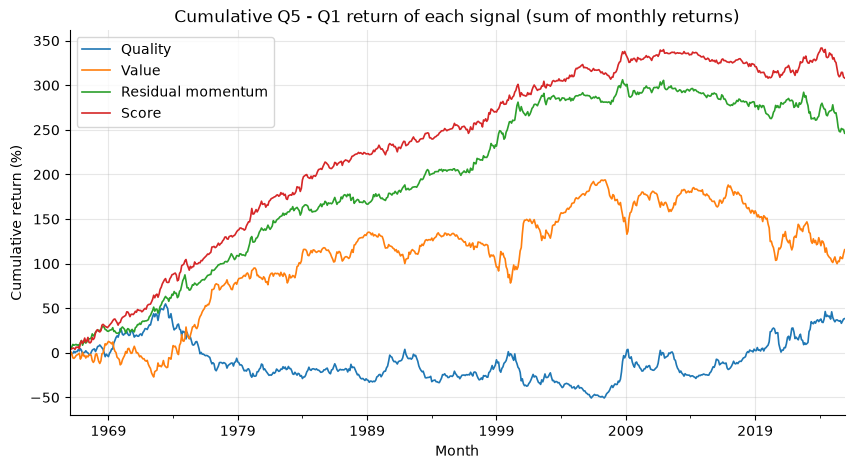

,Q5 - Q1 (% p.a.),FF5 alpha,FF5 + UMD alpha
Quality,0.64 (0.42),3.98 (3.89),3.39 (3.39)
Value,1.93 (0.98),-1.09 (-0.86),1.33 (1.20)
Residual momentum,4.10 (3.42),4.43 (3.41),1.88 (1.56)
Score,5.14 (4.83),5.90 (5.56),4.58 (4.32)


In [16]:
FF5_UMD = ["Mkt-RF", "SMB", "HML", "RMW", "CMA", "UMD"]


def regress(y: pd.Series, factors: list[str], ff: pd.DataFrame = ff5):
    """OLS of the monthly returns y on the factors, with Newey-West standard errors (6 lags)."""
    return sm.OLS(y, sm.add_constant(ff.loc[y.index, factors], has_constant="add")).fit(cov_type="HAC", cov_kwds={"maxlags": 6})


def long_short(x: pd.DataFrame) -> pd.Series:
    """Value-weighted Q5 - Q1 return of a sort on x, dated by the month it is earned."""
    g      = np.ceil(x.rank(pct=True) * 5)
    hi, lo = me.where(g.eq(5)), me.where(g.eq(1))
    s      = ((hi * nxt).sum(min_count=1) / hi.sum() - (lo * nxt).sum(min_count=1) / lo.sum()).dropna()
    return s.set_axis(s.index + pd.offsets.MonthEnd(1))


fmt       = lambda fit: f"{fit.params['const'] * 1200:.2f} ({fit.tvalues['const']:.2f})"
spreads   = pd.DataFrame({k: long_short(x) for k, x in {**comps, "Score": score}.items()}).dropna()
table_sig = pd.DataFrame({k: {"Q5 - Q1 (% p.a.)": fmt(regress(s, [])),
                              "FF5 alpha":        fmt(regress(s, FF5_UMD[:5])),
                              "FF5 + UMD alpha":  fmt(regress(s, FF5_UMD))} for k, s in spreads.items()}).T

ax = (spreads.cumsum() * 100).plot(lw=1.2, title="Cumulative Q5 - Q1 return of each signal (sum of monthly returns)")
ax.set(ylabel="Cumulative return (%)", xlabel="Month")
ax.figure.savefig(FIG / "v2_signal_spreads.pdf")
ax.figure.savefig(FIG / "v2_signal_spreads.png", dpi=150)                         # for the README
plt.show()
table_sig

## 12. The 15 portfolios

3 size buckets × 5 score groups (groups formed within each size bucket), value-weighted. Held at their market weights, the 15 portfolios are exactly the benchmark.

In [17]:
CELLS = [f"{b}-Q{j}" for b in BUCKETS for j in range(1, 6)]
group = sum(np.ceil(score.where(size.eq(b)).rank(pct=True) * 5).fillna(0) for b in BUCKETS)
cell  = (size + "-Q" + group.astype(int).astype(str)).where(universe)

cell_me  = pd.DataFrame({c: me.where(cell.eq(c)).sum() for c in CELLS}).T            # 15 x months, at t
cell_ret = pd.DataFrame({c: (me.where(cell.eq(c)) * nxt).sum(min_count=1) / me.where(cell.eq(c)).sum() for c in CELLS}).T
w_mkt    = cell_me / cell_me.sum()

ok = universe.any() & bench.notna()
assert np.allclose((w_mkt * cell_ret).sum()[ok], bench[ok]), "15 portfolios != benchmark"

## 12b. The 15 portfolios: characteristics

Averages over the months: number of stocks, median market cap, weight in the benchmark, then the return of the next month and the FF5 alpha of its excess return (return − risk-free rate) with its Newey-West t-statistic.

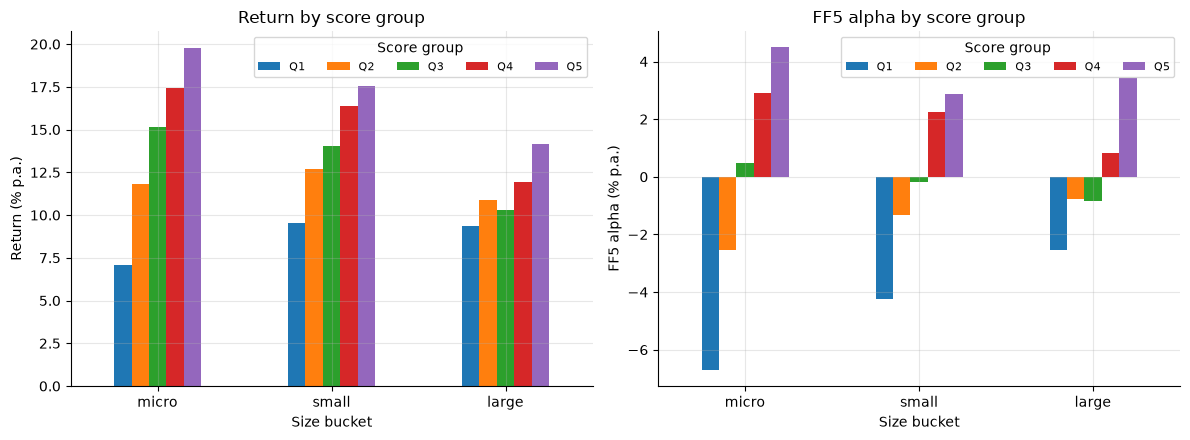

,Stocks,Median market cap ($m),Benchmark weight (%),Return (% p.a.),Volatility (%),FF5 alpha (% p.a.),t (FF5 alpha)
micro-Q1,242.14,132.05,0.50,7.06,23.03,-6.70,-8.55
micro-Q2,242.54,133.68,0.50,11.81,21.23,-2.56,-3.58
micro-Q3,242.53,125.29,0.48,15.18,20.85,0.47,0.65
micro-Q4,242.54,112.46,0.46,17.41,20.73,2.91,4.15
micro-Q5,242.92,92.44,0.40,19.76,20.92,4.49,4.84
small-Q1,126.96,699.41,1.19,9.51,21.70,-4.26,-5.86
small-Q2,127.36,711.03,1.21,12.67,20.30,-1.32,-2.21
small-Q3,127.37,697.43,1.20,14.02,19.80,-0.18,-0.34
small-Q4,127.36,684.45,1.18,16.36,19.69,2.24,3.74
small-Q5,127.77,666.04,1.17,17.56,19.93,2.89,4.37


In [18]:
cell_next = cell_ret.T.set_axis(cell_ret.columns + pd.offsets.MonthEnd(1)).dropna()   # return of t+1, dated t+1
months    = universe.columns[universe.any()]
fits      = {c: regress(cell_next[c] - ff5.loc[cell_next.index, "RF"], FF5_UMD[:5]) for c in CELLS}   # excess returns
chars     = pd.DataFrame({"Stocks":                 {c: cell.eq(c).sum()[months].mean() for c in CELLS},
                          "Median market cap ($m)": {c: me.where(cell.eq(c)).median()[months].mean() for c in CELLS},
                          "Benchmark weight (%)":   w_mkt[months].mean(axis=1) * 100,
                          "Return (% p.a.)":        cell_next.mean() * 1200,
                          "Volatility (%)":         cell_next.std() * np.sqrt(12) * 100,
                          "FF5 alpha (% p.a.)":     {c: fits[c].params["const"] * 1200 for c in CELLS},
                          "t (FF5 alpha)":          {c: fits[c].tvalues["const"] for c in CELLS}})

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, c in zip(axes, ["Return (% p.a.)", "FF5 alpha (% p.a.)"]):
    pd.DataFrame(chars[c].to_numpy().reshape(3, 5), index=BUCKETS, columns=[f"Q{j}" for j in range(1, 6)]).plot.bar(ax=ax, rot=0)
    ax.set(ylabel=c, xlabel="Size bucket", title=f"{c.split(' (')[0]} by score group")
    ax.legend(title="Score group", ncol=5, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "v2_portfolios.pdf")
fig.savefig(FIG / "v2_portfolios.png", dpi=150)                         # for the README
plt.show()
chars.round(2)

## 13. Black-Litterman and optimisation

Each month: covariance of the 15 portfolios over the last 60 months, equilibrium returns $\Pi = \delta \Sigma w^{mkt}$, and one view per size bucket: **the graded spread $Q5 - Q1 + \tfrac12(Q4 - Q2)$ earns 4% a year** (`VIEW`). Then the best risk / return portfolio, long-only, with small bets around the market weights.

**Change vs. v1**: (i) each view is graded, $Q5 - Q1 + \tfrac12(Q4 - Q2)$, so the middle groups carry information too; (ii) the optimiser maximises the BL alpha $(\mu - \Pi)^\top(w - w^{mkt})$ under the TE budget instead of the mean-variance utility. With $\tau = 1/60$ the posterior moves only slightly away from $\Pi$, so v1 used a small part of the 3% TE budget: the signal's alpha was not transferred to the portfolio. Check the realised TE in section 15: well below 3% means `MAX_ACTIVE` is the binding limit.

In [19]:
WINDOW     = 60                                                               # months of past returns
DELTA, TAU = 2.5, 1 / 60                                                      # risk aversion, prior uncertainty
VIEW       = 0.04                                                             # graded view per size bucket, p.a.
LONG_ONLY  = True
MAX_ACTIVE = 0.05                                                             # |w - w_mkt| per portfolio
MAX_TE     = 0.03                                                             # tracking error, p.a.
GRADES     = [-1, -0.5, 0, 0.5, 1]                                            # Q1..Q5 in each view ([-1, 0, 0, 0, 1] = v1)
TE_TARGET  = True                                                             # max BL alpha s.t. TE budget (False = v1)

P = np.zeros((3, 15))
for k, b in enumerate(BUCKETS):
    for j, g in enumerate(GRADES, start=1):
        P[k, CELLS.index(f"{b}-Q{j}")] = g
q = np.full(3, VIEW / 12)


def optimize(mu: np.ndarray, S: np.ndarray, w_m: np.ndarray) -> np.ndarray:
    """Mean-variance weights of the 15 portfolios with the limits above."""
    w = cp.Variable(15)
    cons = [cp.sum(w) == 1, cp.abs(w - w_m) <= MAX_ACTIVE,
            1e4 * 12 * cp.quad_form(w - w_m, cp.psd_wrap(S)) <= (100 * MAX_TE) ** 2]
    if LONG_ONLY:
        cons.append(w >= 0)
    cp.Problem(cp.Maximize(1200 * (mu @ w - DELTA / 2 * cp.quad_form(w, cp.psd_wrap(S)))), cons).solve(solver="CLARABEL")
    w_opt = np.clip(w.value, 0, None) if LONG_ONLY else w.value              # solver noise around 0
    return w_opt / w_opt.sum()



def optimize_te(alpha: np.ndarray, S: np.ndarray, w_m: np.ndarray,
                max_active: float = MAX_ACTIVE, max_te: float = MAX_TE, long_only: bool = LONG_ONLY) -> np.ndarray:
    """Max BL alpha of the active weights, within the TE budget (Grinold-Kahn)."""
    w = cp.Variable(15)
    a = w - w_m
    cons = [cp.sum(w) == 1, cp.abs(a) <= max_active,
            1e4 * 12 * cp.quad_form(a, cp.psd_wrap(S)) <= (100 * max_te) ** 2]
    if long_only:
        cons.append(w >= 0)
    cp.Problem(cp.Maximize(1200 * alpha @ a), cons).solve(solver="CLARABEL")
    w_opt = np.clip(w.value, 0, None) if long_only else w.value
    return w_opt / w_opt.sum()


past    = cell_ret.shift(2, axis=1)                                           # at t: returns earned up to t-1
weights = {}
for t in cell_ret.columns:
    X = past.loc[:, :t].iloc[:, -WINDOW:]                                     # the last 60 months, known at t
    if X.shape[1] < WINDOW or X.isna().any().any() or cell_ret[t].isna().any():
        continue
    S, w_m = np.cov(X.to_numpy()), w_mkt[t].to_numpy()
    pi     = DELTA * S @ w_m                                                  # equilibrium returns
    tS     = TAU * S
    mu     = pi + tS @ P.T @ np.linalg.solve(P @ tS @ P.T + np.diag(np.diag(P @ tS @ P.T)), q - P @ pi)
    assert np.abs(optimize(pi, S, w_m) - w_m).max() < 1e-4, "No view must give the benchmark"
    weights[t] = optimize_te(mu - pi, S, w_m) if TE_TARGET else optimize(mu, S, w_m)
W = pd.DataFrame(weights, index=CELLS)                                        # 15 x months

print(f"Strategy from {W.columns[0]:%Y-%m}; average bet vs. market (%), size (rows) x score group (columns):")
print(((W - w_mkt[W.columns]).mean(axis=1) * 100).to_numpy().reshape(3, 5).round(1))

Strategy from 1970-01; average bet vs. market (%), size (rows) x score group (columns):
[[-0.5 -0.4  0.1  1.4  3.2]
 [-1.2 -1.3 -1.2  0.2  2. ]
 [-5.  -3.4 -0.4  1.9  4.5]]


## 14. Trading costs

Each stock's weight = its portfolio's weight × its value weight in the portfolio. We pay on every trade: 50 bps for micro, 25 bps for small, 10 bps for large stocks. The benchmark pays them too.

In [20]:
COST_BPS = {"micro": 50, "small": 25, "large": 10}                            # one-way


def costs(w: pd.DataFrame) -> pd.Series:
    """Trading cost at each rebalancing t, against the weights of t-1 drifted by the returns of t."""
    r       = ret[w.columns].fillna(0)
    drifted = w.shift(1, axis=1) * (1 + r) / (1 + (w.shift(1, axis=1) * r).sum())
    trade   = (w - drifted).abs()
    bps     = size[w.columns].fillna(size.shift(1, axis=1)[w.columns]).fillna("micro").replace(COST_BPS)
    return (trade * bps.where(trade > 0, 0).astype(float) / 1e4).sum().iloc[1:]   # first month: initial purchase


w_stock = sum((me.where(cell.eq(c))[W.columns] / cell_me.loc[c, W.columns]).fillna(0) * W.loc[c] for c in CELLS)
strat   = (W * cell_ret[W.columns]).sum()                                     # gross, indexed by t
cost_s  = costs(w_stock)
cost_b  = costs(w_bench[W.columns].fillna(0))

to_month = lambda s: s.set_axis(s.index + pd.offsets.MonthEnd(1))            # return of t+1, dated t+1
net_s    = to_month(strat - cost_s.reindex(strat.index).fillna(0))           # cost paid at t, out of the return of t+1
net_b    = to_month(bench[W.columns] - cost_b.reindex(strat.index).fillna(0))
print(f"Costs (% p.a.): strategy {cost_s.mean() * 1200:.2f}, benchmark {cost_b.mean() * 1200:.2f}")

Costs (% p.a.): strategy 0.45, benchmark 0.03


## 14b. Active weights, turnover and limits

Active weight $w - w^{mkt}$ of each portfolio, monthly one-way turnover (half the sum of the absolute trades), ex-ante tracking error $\sqrt{12\,(w - w^{mkt})^\top \Sigma\,(w - w^{mkt})}$, and how often each limit binds.

Turnover (% per month): strategy 9.4, benchmark 0.7; ex-ante TE 1.24% on average
Share of months where the limit binds (%):
Active weight at the limit    100.0
Portfolio at zero weight      100.0
Ex-ante TE at the budget        2.1


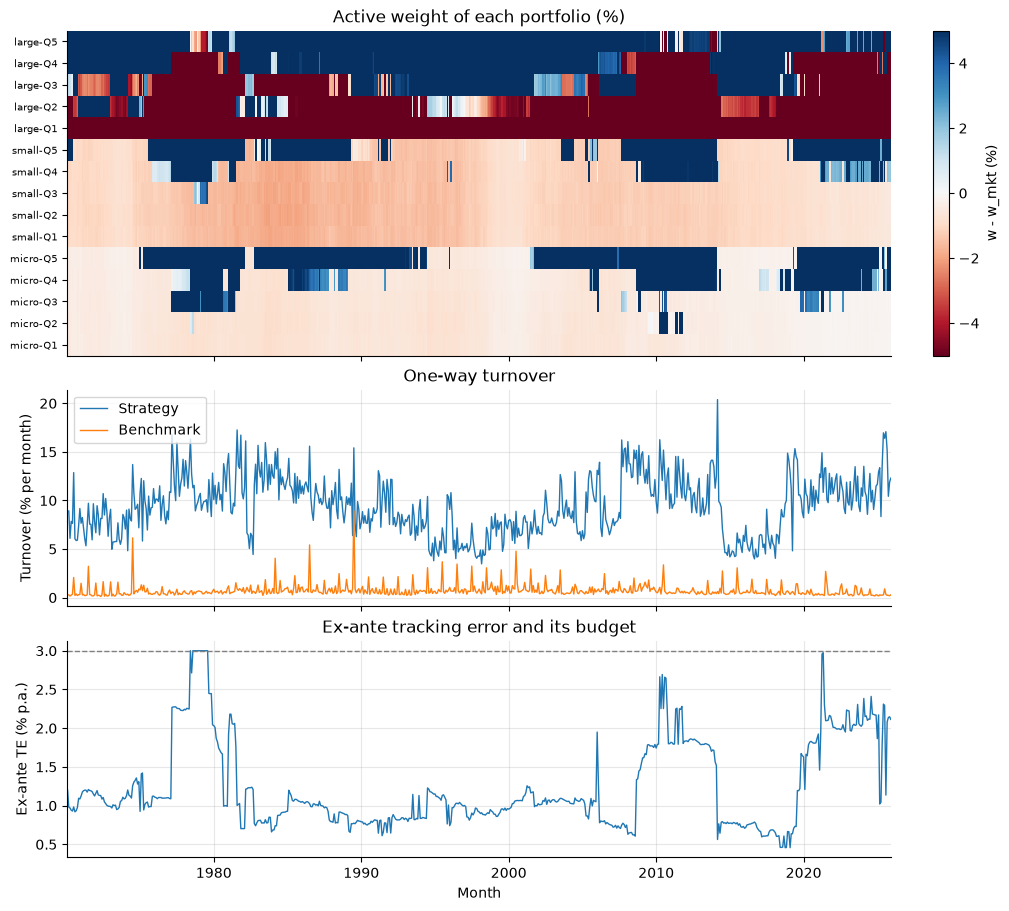

In [21]:
def turnover(w: pd.DataFrame) -> pd.Series:
    """One-way turnover at each rebalancing t, against the weights of t-1 drifted by the returns of t."""
    r       = ret[w.columns].fillna(0)
    drifted = w.shift(1, axis=1) * (1 + r) / (1 + (w.shift(1, axis=1) * r).sum())
    return (w - drifted).abs().sum().iloc[1:] / 2


active = W - w_mkt[W.columns]
te_ex  = pd.Series({t: np.sqrt(12 * active[t].to_numpy() @ np.cov(past.loc[:, :t].iloc[:, -WINDOW:].to_numpy()) @ active[t].to_numpy())
                    for t in W.columns})
turn   = pd.DataFrame({"Strategy": turnover(w_stock), "Benchmark": turnover(w_bench[W.columns].fillna(0))})
limits = pd.Series({"Active weight at the limit": (active.abs() >= MAX_ACTIVE - 1e-4).any().mean(),
                    "Portfolio at zero weight":   (W <= 1e-4).any().mean(),
                    "Ex-ante TE at the budget":   (te_ex >= MAX_TE - 1e-4).mean()}) * 100
print(f"Turnover (% per month): strategy {turn['Strategy'].mean() * 100:.1f}, benchmark {turn['Benchmark'].mean() * 100:.1f}; "
      f"ex-ante TE {te_ex.mean() * 100:.2f}% on average")
print("Share of months where the limit binds (%):\n" + limits.round(1).to_string())

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 9), sharex=True, gridspec_kw={"height_ratios": [3, 2, 2]}, layout="constrained")
mesh = ax1.pcolormesh(active.columns, np.arange(15), active.to_numpy() * 100, cmap="RdBu",
                      vmin=-100 * MAX_ACTIVE, vmax=100 * MAX_ACTIVE, shading="nearest")
ax1.set(yticks=range(15), yticklabels=CELLS, title="Active weight of each portfolio (%)")
ax1.tick_params(axis="y", labelsize=7)
ax1.grid(False)
fig.colorbar(mesh, ax=ax1, label="w - w_mkt (%)")
ax2.plot(turn.index, turn * 100, lw=1, label=list(turn))
ax2.set(ylabel="Turnover (% per month)", title="One-way turnover")
ax2.legend(loc="upper left")
ax3.plot(te_ex.index, te_ex * 100, lw=1)
ax3.axhline(MAX_TE * 100, color="grey", ls="--", lw=1)
ax3.set(ylabel="Ex-ante TE (% p.a.)", xlabel="Month", title="Ex-ante tracking error and its budget")
fig.savefig(FIG / "v2_implementation.pdf")
fig.savefig(FIG / "v2_implementation.png", dpi=150)                         # for the README
plt.show()

## 15. Results

For the whole period and the two halves, **net** of trading costs and **gross** (without costs), to see how much of the result the costs take. **Active** = strategy − benchmark; the information ratio is the active return divided by its volatility.

In [22]:
SPLIT   = pd.Timestamp("1995-12-31")
periods = {"Whole": net_s.index, "Up to 1995": net_s.index[net_s.index <= SPLIT], "From 1996": net_s.index[net_s.index > SPLIT]}
rf      = ff3["RF"]
returns = {"Net": (net_s, net_b), "Gross": (to_month(strat), to_month(bench[W.columns]))}   # (strategy, benchmark)


def stats(r: pd.Series, b: pd.Series) -> pd.Series:
    """Main statistics of the monthly returns r against the benchmark b."""
    ex, act, value = r - rf[r.index], r - b, (1 + r).cumprod()
    t_act = sm.OLS(act.to_numpy(), np.ones(len(act))).fit(cov_type="HAC", cov_kwds={"maxlags": 6}).tvalues[0]
    return pd.Series({"Return (% p.a.)":   r.mean() * 1200,
                      "Volatility (%)":    r.std() * np.sqrt(12) * 100,
                      "Sharpe":            ex.mean() / ex.std() * np.sqrt(12),
                      "Max drawdown (%)":  (value / value.cummax().clip(lower=1) - 1).min() * 100,
                      "Active (% p.a.)":   act.mean() * 1200,
                      "t (active)":        t_act,
                      "Tracking error (%)": act.std() * np.sqrt(12) * 100,
                      "Information ratio": act.mean() / act.std() * np.sqrt(12)})


table = pd.concat({p: pd.DataFrame({c: stats(s[d], b[d]) for c, (s, b) in returns.items()}) for p, d in periods.items()}, axis=1)
table.loc["Benchmark return (% p.a.)"] = [b[d].mean() * 1200 for d in periods.values() for s, b in returns.values()]
table.round(2)

Whole        Up to 1995        From 1996       
                             Net  Gross        Net  Gross       Net  Gross
Return (% p.a.)            12.63  13.08      14.02  14.48     11.42  11.87
Volatility (%)             15.62  15.62      15.60  15.60     15.66  15.65
Sharpe                      0.53   0.56       0.46   0.49      0.58   0.61
Max drawdown (%)          -49.24 -48.73     -43.61 -43.42    -49.24 -48.73
Active (% p.a.)             0.53   0.96       1.11   1.54      0.03   0.46
t (active)                  2.75   4.86       4.17   5.48      0.12   1.78
Tracking error (%)          1.33   1.34       1.21   1.22      1.42   1.42
Information ratio           0.40   0.72       0.92   1.26      0.02   0.32
Benchmark return (% p.a.)  12.09  12.12      12.91  12.94     11.39  11.41

## 15b. Other risk statistics

Same periods, net and gross, with the benchmark (net) for comparison. VaR 5%: 5th percentile of the monthly returns; CVaR 5%: average return below it. Beta against the benchmark; hit rate: share of months the strategy beats the benchmark.

In [23]:
def risk_stats(r: pd.Series, b: pd.Series) -> pd.Series:
    """Other statistics of the monthly returns r against the benchmark b."""
    ex, value = r - rf[r.index], (1 + r).cumprod()
    peak      = value.cummax().clip(lower=1)
    under     = value < peak
    cagr      = value.iloc[-1] ** (12 / len(r)) - 1
    var       = r.quantile(0.05)
    return pd.Series({"CAGR (%)":                  cagr * 100,
                      "Sortino":                   ex.mean() / np.sqrt((ex.clip(upper=0) ** 2).mean()) * np.sqrt(12),
                      "Calmar":                    cagr / -(value / peak - 1).min(),
                      "Longest drawdown (months)": under.groupby((~under).cumsum()).sum().max(),
                      "Skewness":                  r.skew(),
                      "Excess kurtosis":           r.kurt(),
                      "VaR 5% (% per month)":      var * 100,
                      "CVaR 5% (% per month)":     r[r <= var].mean() * 100,
                      "Beta":                      np.cov(r, b)[0, 1] / b.var(),
                      "Hit rate (%)":              (r > b).mean() * 100})


table_risk = pd.concat({p: pd.DataFrame({**{c: risk_stats(s[d], b[d]) for c, (s, b) in returns.items()},
                                         "Benchmark": risk_stats(net_b[d], net_b[d])}) for p, d in periods.items()}, axis=1)
table_risk.loc[["Beta", "Hit rate (%)"], pd.IndexSlice[:, "Benchmark"]] = np.nan   # benchmark against itself
table_risk.round(2)

Whole                  Up to 1995                   \
                             Net  Gross Benchmark        Net  Gross Benchmark   
CAGR (%)                   12.01  12.51     11.45      13.58  14.09     12.34   
Sortino                     0.78   0.83      0.74       0.69   0.74      0.58   
Calmar                      0.24   0.26      0.23       0.31   0.32      0.28   
Longest drawdown (months)  64.00  64.00     66.00      38.00  38.00     44.00   
Skewness                   -0.51  -0.51     -0.49      -0.45  -0.45     -0.37   
Excess kurtosis             1.93   1.93      1.72       3.04   3.03      2.63   
VaR 5% (% per month)       -7.00  -6.96     -6.92      -5.71  -5.65     -5.71   
CVaR 5% (% per month)      -9.92  -9.87     -9.74      -9.61  -9.57     -9.42   
Beta                        1.01   1.01       NaN       1.00   1.00       NaN   
Hit rate (%)               56.48  60.66       NaN      65.27  68.81       NaN   

                          From 1996                   
                                Net  Gross Benchmark  
CAGR (%)                      10.67  11.17     10.68  
Sortino                        0.86   0.91      0.87  
Calmar                         0.22   0.23      0.22  
Longest drawdown (months)     64.00  64.00     66.00  
Skewness                      -0.56  -0.56     -0.60  
Excess kurtosis                1.03   1.03      0.93  
VaR 5% (% per month)          -7.78  -7.70     -7.41  
CVaR 5% (% per month)         -9.93  -9.88     -9.79  
Beta                           1.01   1.01       NaN  
Hit rate (%)                  48.89  53.61       NaN

## 16. Alpha

Regression of the active return on the factors (CAPM, FF3, FF5, FF5 + UMD), net and gross of costs: a significant positive **alpha** is a return the factors do not explain. FF3 uses the 3-factor file (its SMB differs from the FF5 one). Alpha in % p.a., Newey-West t-statistic (6 lags) in parentheses.

In [24]:
models = {"CAPM":      (ff5, ["Mkt-RF"]),
          "FF3":       (ff3, ["Mkt-RF", "SMB", "HML"]),
          "FF5":       (ff5, ["Mkt-RF", "SMB", "HML", "RMW", "CMA"]),
          "FF5 + UMD": (ff5, ["Mkt-RF", "SMB", "HML", "RMW", "CMA", "UMD"])}
alpha  = {}
for c, (s, b) in returns.items():
    for p, d in periods.items():
        for m, (ff, f) in models.items():
            fit = sm.OLS(s[d] - b[d], sm.add_constant(ff.loc[d, f])).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
            alpha[(m, p, c)] = f"{fit.params['const'] * 1200:.2f} ({fit.tvalues['const']:.2f})"
table_alpha = pd.Series(alpha).unstack([1, 2]).reindex(index=list(models), columns=pd.MultiIndex.from_product([periods, returns]))
table_alpha

Whole                Up to 1995                   From 1996  \
                   Net        Gross          Net        Gross            Net   
CAPM       0.49 (2.41)  0.91 (4.47)  1.13 (4.33)  1.55 (5.70)  -0.09 (-0.31)   
FF3        0.31 (1.59)  0.74 (3.76)  0.97 (3.73)  1.40 (5.15)  -0.17 (-0.62)   
FF5        0.32 (1.70)  0.75 (3.96)  0.82 (2.82)  1.25 (4.17)  -0.13 (-0.48)   
FF5 + UMD  0.20 (1.07)  0.63 (3.35)  0.41 (1.50)  0.84 (2.96)  -0.14 (-0.52)   

                        
                 Gross  
CAPM       0.34 (1.21)  
FF3        0.26 (0.95)  
FF5        0.29 (1.09)  
FF5 + UMD  0.29 (1.07)

## 16b. Factor exposures

FF5 + UMD regression of the net active return: the loadings show which factors the active return comes from. Coefficient (Newey-West t-statistic); alpha in % p.a.

In [25]:
loadings = {}
for p, d in periods.items():
    fit = regress(net_s[d] - net_b[d], FF5_UMD)
    loadings[p] = [fmt(fit)] + [f"{fit.params[f]:.3f} ({fit.tvalues[f]:.2f})" for f in FF5_UMD] + [f"{fit.rsquared:.2f}"]
table_loadings = pd.DataFrame(loadings, index=["Alpha (% p.a.)", *FF5_UMD, "R-squared"])
table_loadings

,Whole,Up to 1995,From 1996
Alpha (% p.a.),0.20 (1.07),0.41 (1.50),-0.14 (-0.52)
Mkt-RF,0.010 (2.28),0.002 (0.24),0.011 (1.93)
SMB,0.017 (1.40),0.020 (1.21),0.022 (1.44)
HML,0.047 (4.68),0.024 (1.78),0.051 (4.83)
RMW,-0.001 (-0.05),-0.001 (-0.07),0.001 (0.11)
CMA,-0.011 (-0.88),0.014 (0.79),-0.021 (-1.60)
UMD,0.015 (2.27),0.045 (4.76),0.001 (0.27)
R-squared,0.13,0.23,0.19


## 17. Chart

Value of \$1 invested, net of costs (log scale), and drawdowns.

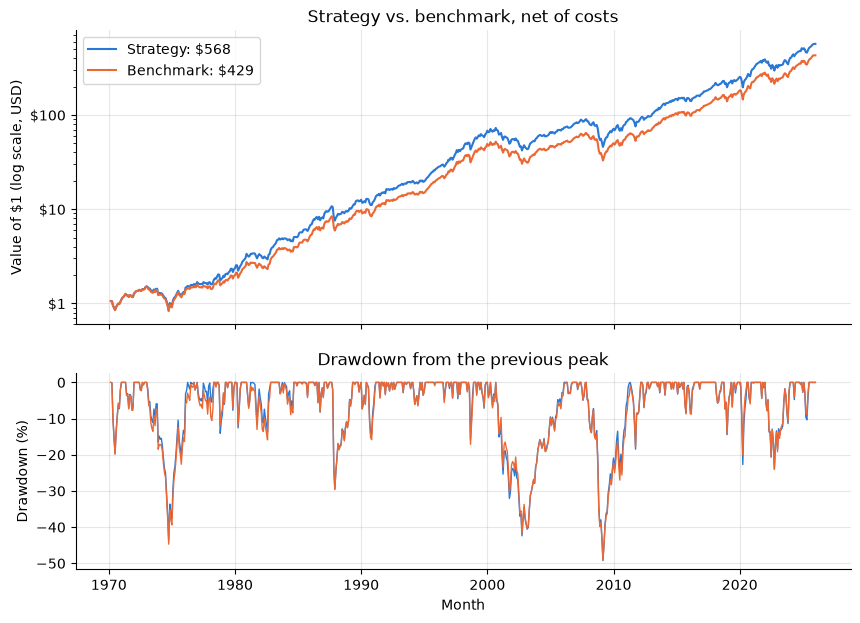

In [26]:
colors = {"Strategy": "#2a78d6", "Benchmark": "#eb6834"}

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
for name, r in {"Strategy": net_s, "Benchmark": net_b}.items():
    value = (1 + r).cumprod()
    ax1.plot(value.index, value, color=colors[name], lw=1.5, label=f"{name}: ${value.iloc[-1]:,.0f}")
    ax2.plot(value.index, (value / value.cummax().clip(lower=1) - 1) * 100, color=colors[name], lw=1)
ax1.set_yscale("log")
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax1.set(ylabel="Value of $1 (log scale, USD)", title="Strategy vs. benchmark, net of costs")
ax1.legend(loc="upper left")
ax2.set(ylabel="Drawdown (%)", xlabel="Month", title="Drawdown from the previous peak")
fig.savefig(FIG / "v2_strategy_vs_benchmark.pdf")
fig.savefig(FIG / "v2_strategy_vs_benchmark.png", dpi=150)                         # for the README
plt.show()

## 17b. Active return over time

Value of the strategy relative to the benchmark (both start at 1), net and gross of costs, and the active return over rolling 36 months. The dashed line is the split of section 15.

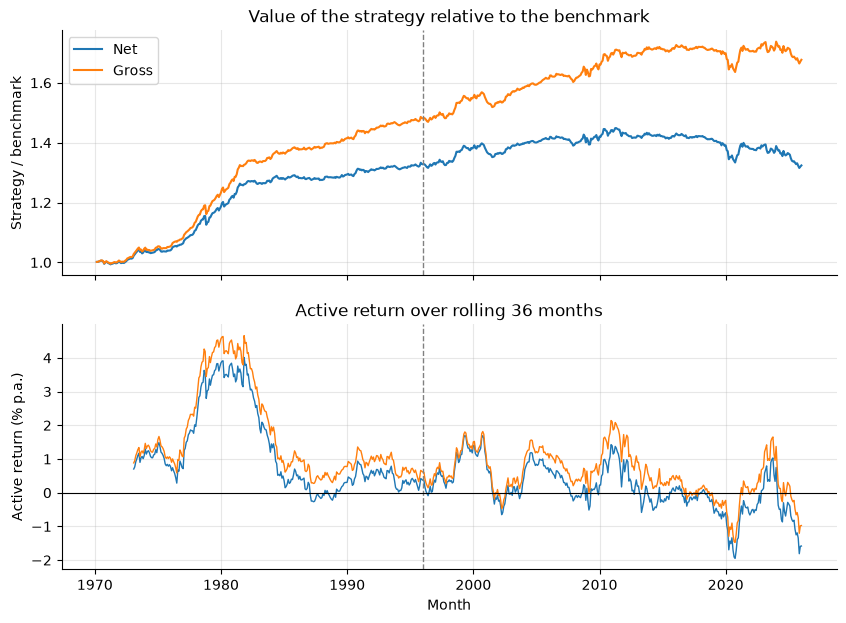

In [27]:
ROLL = 36                                                                     # months

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for c, (s, b) in returns.items():
    ax1.plot(s.index, (1 + s).cumprod() / (1 + b).cumprod(), lw=1.5, label=c)
    ax2.plot(s.index, (s - b).rolling(ROLL).mean() * 1200, lw=1, label=c)
for ax in (ax1, ax2):
    ax.axvline(SPLIT, color="grey", ls="--", lw=1)
ax2.axhline(0, color="black", lw=0.8)
ax1.set(ylabel="Strategy / benchmark", title="Value of the strategy relative to the benchmark")
ax2.set(ylabel="Active return (% p.a.)", xlabel="Month", title=f"Active return over rolling {ROLL} months")
ax1.legend(loc="upper left")
fig.savefig(FIG / "v2_active_return.pdf")
fig.savefig(FIG / "v2_active_return.png", dpi=150)                         # for the README
plt.show()

## 17c. By decade and market state

Active return in each decade, and in the months the benchmark goes up or down, net and gross. % p.a., Newey-West t-statistic in parentheses.

In [28]:
groups  = {f"{y}s": net_s.index[(net_s.index.year >= y) & (net_s.index.year < y + 10)] for y in range(1970, 2030, 10)}
groups |= {"Benchmark up": net_s.index[(net_b > 0).to_numpy()], "Benchmark down": net_s.index[(net_b <= 0).to_numpy()]}
table_regimes = pd.DataFrame({c: {g: fmt(regress(s[d] - b[d], [])) for g, d in groups.items()} for c, (s, b) in returns.items()})
table_regimes.insert(0, "Months", [len(d) for d in groups.values()])
table_regimes

,Months,Net,Gross
1970s,119,1.77 (3.56),2.16 (4.03)
1980s,120,0.88 (2.24),1.40 (3.45)
1990s,120,0.65 (2.14),0.90 (3.04)
2000s,120,0.29 (0.81),0.72 (1.88)
2010s,120,-0.18 (-0.66),0.26 (0.93)
2020s,72,-0.73 (-0.83),-0.11 (-0.12)
Benchmark up,419,0.49 (1.74),0.91 (3.15)
Benchmark down,252,0.61 (1.44),1.03 (2.52)


## 18. Robustness

The backtest of section 13 (TE-target optimiser) again, with one change at a time. For information only: the main strategy is not changed after seeing these results (data snooping). *Rolling view*: $q_t$ = average graded spread $P\,r$ of the 15 portfolios over the 60 months known at $t$, instead of the fixed view. *Ledoit-Wolf*: shrunk covariance instead of the sample one. *Short selling allowed*: no long-only constraint, the ±5% active limit and the TE budget stay; the cost of borrowing the shorted stocks is not modelled, so this result is optimistic. The \$1 price filter needs the whole notebook re-run with `MIN_PRICE = 1`.

In [29]:
def backtest(max_active: float = MAX_ACTIVE, max_te: float = MAX_TE, ledoit_wolf: bool = False, rolling_view: bool = False,
             long_only: bool = LONG_ONLY) -> tuple[pd.Series, pd.DataFrame]:
    """Net monthly return (dated t+1) and weights of the 15 portfolios of the strategy of section 13 with other settings."""
    weights = {}
    for t in W.columns:
        X      = past.loc[:, :t].iloc[:, -WINDOW:].to_numpy()                # the last 60 months, known at t
        S      = LedoitWolf().fit(X.T).covariance_ if ledoit_wolf else np.cov(X)
        w_m    = w_mkt[t].to_numpy()
        pi, tS = DELTA * S @ w_m, TAU * S
        q_t    = P @ X.mean(axis=1) if rolling_view else q
        mu     = pi + tS @ P.T @ np.linalg.solve(P @ tS @ P.T + np.diag(np.diag(P @ tS @ P.T)), q_t - P @ pi)
        weights[t] = optimize_te(mu - pi, S, w_m, max_active, max_te, long_only)
    Wv  = pd.DataFrame(weights, index=CELLS)
    w_s = sum((me.where(cell.eq(c))[Wv.columns] / cell_me.loc[c, Wv.columns]).fillna(0) * Wv.loc[c] for c in CELLS)
    return to_month((Wv * cell_ret[Wv.columns]).sum() - costs(w_s).reindex(Wv.columns).fillna(0)), Wv


variants = {"Base":                   {},
            "Active limit 2.5%":      {"max_active": 0.025},
            "Active limit 10%":       {"max_active": 0.10},
            "TE budget 2%":           {"max_te": 0.02},
            "Ledoit-Wolf covariance": {"ledoit_wolf": True},
            "Rolling view":           {"rolling_view": True},
            "Short selling allowed":  {"long_only": False}}
robust = {}
for v, kw in variants.items():
    r, Wv = backtest(**kw)
    act   = r - net_b
    robust[v] = {"Active (% p.a.)":    fmt(regress(act, [])),
                 "Active from 1996":   fmt(regress(act[act.index > SPLIT], [])),
                 "Tracking error (%)": f"{act.std() * np.sqrt(12) * 100:.2f}",
                 "FF5 + UMD alpha":    fmt(regress(act, FF5_UMD)),
                 "Short weights (%)":  f"{abs(Wv.clip(upper=0).sum().mean()) * 100:.2f}"}   # average sum of the negative weights
    if v == "Base":
        assert np.allclose(act, net_s - net_b), "Base must reproduce the strategy"
table_robust = pd.DataFrame(robust).T
table_robust

,Active (% p.a.),Active from 1996,Tracking error (%),FF5 + UMD alpha,Short weights (%)
Base,0.53 (2.75),0.03 (0.12),1.33,0.20 (1.07),0.00
Active limit 2.5%,0.24 (2.17),-0.07 (-0.49),0.76,0.08 (0.73),0.00
Active limit 10%,0.91 (2.90),0.20 (0.45),2.08,0.44 (1.55),0.00
TE budget 2%,0.51 (2.77),0.06 (0.22),1.26,0.22 (1.26),0.00
Ledoit-Wolf covariance,0.58 (3.19),0.13 (0.49),1.25,0.28 (1.64),0.00
Rolling view,0.35 (1.43),-0.30 (-0.91),1.65,-0.02 (-0.10),0.00
Short selling allowed,0.64 (2.20),-0.33 (-0.89),1.98,0.37 (1.44),22.17


## 18b. Simple long-only alternatives

Without Black-Litterman: hold only the best score groups, value-weighted. For a set $G$ of the 15 portfolios, the weight of stock $i$ at $t$ is $w_{i,t} = ME_{i,t} / \sum_{j \in G_t} ME_{j,t}$ for $i \in G_t$ (0 otherwise); it earns the return of $t+1$ and pays the same trading costs as the strategy. Q5 and Q4 + Q5, over all sizes and in large caps only (the most investable version). Same evaluation as sections 15–16: active return against the benchmark, % p.a., Newey-West t-statistic in parentheses.

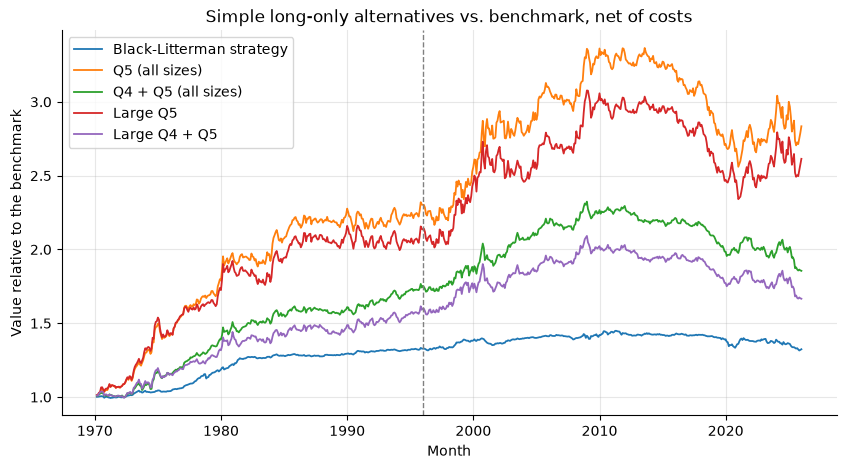

,"Return, net (% p.a.)","Active, net","Active, gross","Active from 1996, net",Tracking error (%),Information ratio,"FF5 + UMD alpha, net",Turnover (% per month),Costs (% p.a.)
Black-Litterman strategy,12.63,0.53 (2.75),0.96 (4.86),0.03 (0.12),1.33,0.40,0.20 (1.07),9.4,0.45
Q5 (all sizes),14.01,1.92 (3.08),2.82 (4.52),0.79 (0.93),4.77,0.40,1.77 (2.77),33.0,0.93
Q4 + Q5 (all sizes),13.20,1.10 (2.74),1.72 (4.25),0.21 (0.39),3.06,0.36,0.97 (2.27),22.6,0.64
Large Q5,13.85,1.76 (2.59),2.54 (3.74),0.76 (0.83),5.21,0.34,1.75 (2.59),33.6,0.81
Large Q4 + Q5,12.98,0.89 (2.01),1.42 (3.20),0.14 (0.24),3.47,0.26,0.87 (1.94),22.9,0.55


In [30]:
SIMPLE = {"Q5 (all sizes)":      [f"{b}-Q5" for b in BUCKETS],
          "Q4 + Q5 (all sizes)": [f"{b}-Q{j}" for b in BUCKETS for j in (4, 5)],
          "Large Q5":            ["large-Q5"],
          "Large Q4 + Q5":       ["large-Q4", "large-Q5"]}


def simple_portfolio(cells: list[str]) -> tuple[pd.Series, pd.Series, pd.DataFrame]:
    """Gross and net monthly returns (dated t+1) and stock weights of the value-weighted portfolio of the given cells."""
    m     = me.where(cell.isin(cells))[W.columns]
    w     = (m / m.sum()).fillna(0)
    gross = to_month((w * nxt[W.columns]).sum())
    return gross, gross - to_month(costs(w).reindex(W.columns).fillna(0)), w


portfolios = {"Black-Litterman strategy": (returns["Gross"][0], net_s, w_stock),
              **{k: simple_portfolio(v) for k, v in SIMPLE.items()}}
rows = {}
for name, (gross, net, w) in portfolios.items():
    act_n, act_g = net - net_b, gross - returns["Gross"][1]
    rows[name] = {"Return, net (% p.a.)":     f"{net.mean() * 1200:.2f}",
                  "Active, net":              fmt(regress(act_n, [])),
                  "Active, gross":            fmt(regress(act_g, [])),
                  "Active from 1996, net":    fmt(regress(act_n[act_n.index > SPLIT], [])),
                  "Tracking error (%)":       f"{act_n.std() * np.sqrt(12) * 100:.2f}",
                  "Information ratio":        f"{act_n.mean() / act_n.std() * np.sqrt(12):.2f}",
                  "FF5 + UMD alpha, net":     fmt(regress(act_n, FF5_UMD)),
                  "Turnover (% per month)":   f"{turnover(w).mean() * 100:.1f}",
                  "Costs (% p.a.)":           f"{(gross - net).mean() * 1200:.2f}"}
table_simple = pd.DataFrame(rows).T

fig, ax = plt.subplots()
for name, (gross, net, w) in portfolios.items():
    ax.plot(net.index, (1 + net).cumprod() / (1 + net_b).cumprod(), lw=1.3, label=name)
ax.axvline(SPLIT, color="grey", ls="--", lw=1)
ax.set(ylabel="Value relative to the benchmark", xlabel="Month", title="Simple long-only alternatives vs. benchmark, net of costs")
ax.legend(loc="upper left")
fig.savefig(FIG / "v2_simple_alternatives.pdf")
fig.savefig(FIG / "v2_simple_alternatives.png", dpi=150)                         # for the README
plt.show()
table_simple

## 19. Tables for the report

The main tables, saved in LaTeX in `results/tables/` for Overleaf.

In [31]:
tables = {"performance": table, "ratios_by_sector": table_sectors, "risk": table_risk, "alpha": table_alpha, "loadings": table_loadings, "signals": table_sig,
          "portfolios": chars, "regimes": table_regimes, "robustness": table_robust, "simple": table_simple}
for name, t in tables.items():
    t.to_latex(TAB / f"v2_{name}.tex", float_format="%.2f")
print("Saved: " + ", ".join(f"v2_{name}.tex" for name in tables))

Saved: v2_performance.tex, v2_ratios_by_sector.tex, v2_risk.tex, v2_alpha.tex, v2_loadings.tex, v2_signals.tex, v2_portfolios.tex, v2_regimes.tex, v2_robustness.tex, v2_simple.tex
